# 08. Figure 1 Sankey panels, tunable

Draws the NDC panel and the online panel **separately**, so each can be exported and
placed by hand, and re-runs in a second when a setting changes.

Everything adjustable lives in the **Settings** cell. Change a value, re-run that cell and
the panel cell below it. Nothing else needs to be touched.

| setting | what it does |
|---|---|
| `COLORS` | the six group colours |
| `ALPHA` | ribbon transparency |
| `TOPIC_GAP` / `GROUP_GAP` | space between the small topic blocks / between groups |
| `FIGSIZE` | width and height in inches |
| `SHOW_LABELS` | topic names on or off |
| `LABEL_MIN_SHARE` | a topic is labelled only above this share |
| `CURVE` | how much the ribbons bend |
| `NODE_WIDTH` / `NODE_COLOR` | the dark bars |
| `SHOW_GROUP_PCT` | the `G1: 24.5%` labels |

In [ ]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), 'src'))  # the modules the notebooks import live in src/


In [148]:
import os, sys, warnings
warnings.filterwarnings('ignore')
sys.path.insert(0, '.')
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle
import config as cfg, figures as F, results as rs

In [149]:
OUT = 'output/figures'
os.makedirs(OUT, exist_ok=True)

GROUPS  = ['G1', 'G2', 'G3', 'G4', 'G5', 'G6']
TOPICS  = [f'T{i}' for i in range(1, 39)]
GRP_OF  = {f'T{i}': g for g, ids in cfg.TOPIC_GROUPS_TW.items() for i in ids}

ga  = pd.read_csv('output/GA_topics.csv', low_memory=False)
rec = pd.read_parquet('output/topic_recall_2022.parquet')
ndc_t, ndc_g = rs.ndc_shares(ga)
onl_t, onl_g = rs.online_shares(rec)

SHARES = {'ndc': ndc_t.ndc_share, 'online': onl_t.online_share}
GSHARE = {'ndc': ndc_g,           'online': onl_g}

print('topic shares sum to', round(SHARES['ndc'].sum(), 3), 'and', round(SHARES['online'].sum(), 3))
pd.DataFrame({'NDC %': 100*ndc_g, 'online %': 100*onl_g}).round(1)

topic shares sum to 1.0 and 1.0


,NDC %,online %
G1,24.5,12.9
G2,24.7,28.6
G3,27.3,21.1
G4,11.7,8.2
G5,7.1,18.4
G6,4.8,10.8


## Settings

In [178]:
# ---- colours -------------------------------------------------------------------
# The pure group colour. Ribbons are this colour at ALPHA; the middle node bars use it
# at full strength, which is what the published figure does.
COLORS = {
    'G1': '#9E4565',   # emission accounting and targets
    'G2': '#CD99AB',   # sector mitigation
    'G3': '#77ADB5',   # adaptation
    'G4': '#B3AFAA',   # governance and regulation
    'G5': '#ABBFC0',   # social inclusion
    'G6': '#B0ABCE',   # finance and carbon markets
}
ALPHA = 0.5           # ribbon transparency; 0.51 reproduces the published ribbons

# ---- node bars -----------------------------------------------------------------
TOPIC_NODE_WIDTH = 0.005     # the 38 small bars on the outer side
TOPIC_NODE_COLOR = '#38403A' # dark green-grey, sampled from the published figure
GROUP_NODE_WIDTH = 0.005      # the 6 bars on the inner side
GROUP_NODE_COLOR = None      # None = each group's own colour; or a hex such as '#38403A'

# ---- vertical extent -----------------------------------------------------------
# The two columns do not have to span the same height. The group column is shorter in
# the published figure because the word clouds sit beside it.
TOPIC_TOP, TOPIC_BOT = 0.975, 0.015
GROUP_TOP, GROUP_BOT = 0.975, 0.105

# ---- spacing and size ----------------------------------------------------------
TOPIC_GAP = 0.004     # gap between the 38 small blocks
GROUP_GAP = 0.013      # gap between the 6 group blocks
FIGSIZE   = (12, 12.5)  # inches, one panel
CURVE     = 0.42       # 0.5 = S-curve with a straight middle, lower = flatter

# Where the two columns sit across the panel, as a fraction of its width. The gap
# between them is how long the ribbons run, so widen it to stretch the Sankey sideways.
# These are for the NDC panel; the online panel mirrors them automatically.
PANEL_LABEL_X = 0.28   # where the topic labels end
PANEL_TOPIC_X = 0.30   # the column of 38 nodes
PANEL_GROUP_X = 0.86   # the column of 6 nodes

# ---- labels --------------------------------------------------------------------
SHOW_LABELS     = True
LABEL_MIN_SHARE = 0.0125   # label a topic only if its share is at least this
LABEL_FONT      = 'Times New Roman'
LABEL_CODE_BOLD = True     # the 'T1:' part in bold, the name in regular weight
LABEL_CODE_GAP  = 0.004    # space between 'T1:' and the name, in axes units
TITLE_FONT      = 'Times New Roman'   # headers, panel titles and group names
LABEL_FONTSIZE  = 17
LABEL_SPACING   = 0.026    # minimum vertical gap between two labels
LEADER_COLOR    = '#B5B5B5'

SHOW_GROUP_PCT = True      # False removes the G1: 24.5% labels entirely
PCT_SIDES      = ('ndc', 'online')   # or just ('ndc',) to keep them on one panel only
PCT_LABEL      = lambda g, pct: f'{g}: {pct:.1f}%'
#   '24.5%' only      ->  lambda g, pct: f'{pct:.1f}%'
#   'G1' only         ->  lambda g, pct: g
#   no decimal        ->  lambda g, pct: f'{g}: {pct:.0f}%'
#   full group name   ->  lambda g, pct: f'{F.GROUP_LABELS[g]}  {pct:.1f}%'
PCT_FONTSIZE   = 18
PCT_OFFSET     = 0.014     # distance from the bar; negative puts it inside the ribbon
PCT_COLOR      = '#222222'
PCT_WEIGHT     = 'bold'    # or 'normal'
PCT_BOX        = True      # the box behind the text; False removes it
PCT_BOX_COLOR  = 'white'
PCT_BOX_ALPHA  = 0.5       # 0 = fully transparent, 1 = solid
PCT_BOX_PAD    = 1.8       # padding around the text, in points

DPI = 300

## The drawing function

In [179]:
def _topic_label(ax, x, y, code, name, ha, fontsize, font=None):
    """Draw 'T1: name' with the code in bold and the name in regular weight."""
    kw = dict(va='center', fontsize=fontsize, color='#1A1A1A',
          fontfamily=font or LABEL_FONT)
    cw = 'bold' if LABEL_CODE_BOLD else 'normal'
    if not LABEL_CODE_BOLD:
        return [ax.text(x, y, f'{code}: {name}', ha=ha, **kw)]
    fig = ax.figure
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    probe = ax.text(0, -5, f'{code}:', fontweight=cw, **kw)
    cwidth = probe.get_window_extent(renderer=r).transformed(
        ax.transAxes.inverted()).width
    probe.remove()
    if ha == 'right':
        n = ax.text(x, y, name, ha='right', fontweight='normal', **kw)
        nwidth = n.get_window_extent(renderer=r).transformed(
            ax.transAxes.inverted()).width
        c = ax.text(x - nwidth - LABEL_CODE_GAP, y, f'{code}:', ha='right',
                    fontweight=cw, **kw)
    else:
        c = ax.text(x, y, f'{code}:', ha='left', fontweight=cw, **kw)
        n = ax.text(x + cwidth + LABEL_CODE_GAP, y, name, ha='left',
                    fontweight='normal', **kw)
    return [c, n]


def _layout(side):
    s = SHARES[side]
    u = (TOPIC_TOP - TOPIC_BOT) - 37 * TOPIC_GAP
    y, tpos = TOPIC_TOP, {}
    for t in TOPICS:                       # numerical order, so ribbons cross
        h = float(s[t]) * u
        tpos[t] = (y - h, y)
        y -= h + TOPIC_GAP
    ug = (GROUP_TOP - GROUP_BOT) - 5 * GROUP_GAP
    y, gpos = GROUP_TOP, {}
    for g in GROUPS:
        h = float(GSHARE[side][g]) * ug
        gpos[g] = (y - h, y)
        y -= h + GROUP_GAP
    return tpos, gpos


def _ribbon(ax, x0, x1, y0a, y0b, y1a, y1b, color):
    c0, c1 = x0 + (x1 - x0) * CURVE, x0 + (x1 - x0) * (1 - CURVE)
    v = [(x0,y0a),(c0,y0a),(c1,y1a),(x1,y1a),(x1,y1b),(c1,y1b),(c0,y0b),(x0,y0b),(x0,y0a)]
    c = [Path.MOVETO,Path.CURVE4,Path.CURVE4,Path.CURVE4,Path.LINETO,
         Path.CURVE4,Path.CURVE4,Path.CURVE4,Path.CLOSEPOLY]
    ax.add_patch(PathPatch(Path(v, c), facecolor=color, edgecolor='none',
                           alpha=ALPHA, lw=0, zorder=2))


def _spread(ys, lo, hi, gap):
    """Push labels apart without reordering them."""
    out = list(ys)
    for i in range(1, len(out)):
        if out[i-1] - out[i] < gap:
            out[i] = out[i-1] - gap
    if out and out[-1] < lo:
        out[-1] = lo
        for i in range(len(out)-2, -1, -1):
            out[i] = max(out[i], out[i+1] + gap)
    if out and out[0] > hi:
        out[0] = hi
        for i in range(1, len(out)):
            out[i] = min(out[i], out[i-1] - gap)
    return out


def sankey(side, title=None, save=None):
    """side='ndc' puts topics on the left, side='online' puts them on the right."""
    tpos, gpos = _layout(side)
    ht, hg = TOPIC_NODE_WIDTH / 2, GROUP_NODE_WIDTH / 2
    if side == 'ndc':
        x_topic, x_group, label_x, ha = (PANEL_TOPIC_X, PANEL_GROUP_X,
                                         PANEL_LABEL_X, 'right')
    else:
        x_topic, x_group, label_x, ha = (1 - PANEL_TOPIC_X, 1 - PANEL_GROUP_X,
                                         1 - PANEL_LABEL_X, 'left')

    fig = plt.figure(figsize=FIGSIZE, dpi=150)
    ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')

    cursor = {g: gpos[g][1] for g in GROUPS}
    for t in TOPICS:
        g = GRP_OF[t]
        a, b = tpos[t]
        gh = (gpos[g][1] - gpos[g][0]) * (float(SHARES[side][t]) / float(GSHARE[side][g]))
        gb = cursor[g]; ga_ = gb - gh; cursor[g] = ga_
        if side == 'ndc':
            _ribbon(ax, x_topic + ht, x_group - hg, a, b, ga_, gb, COLORS[g])
        else:
            _ribbon(ax, x_group + hg, x_topic - ht, ga_, gb, a, b, COLORS[g])
        ax.add_patch(Rectangle((x_topic - ht, a), TOPIC_NODE_WIDTH, b - a,
                               facecolor=TOPIC_NODE_COLOR, edgecolor='none', zorder=3))

    for g in GROUPS:
        a, b = gpos[g]
        ax.add_patch(Rectangle((x_group - hg, a), GROUP_NODE_WIDTH, b - a,
                               facecolor=GROUP_NODE_COLOR or COLORS[g],
                               edgecolor='none', zorder=3))
        if SHOW_GROUP_PCT and side in PCT_SIDES:
            dx, pha = ((-PCT_OFFSET, 'right') if side == 'ndc'
                       else (PCT_OFFSET, 'left'))
            ax.text(x_group + dx, (a + b) / 2,
                    PCT_LABEL(g, 100 * GSHARE[side][g]),
                    ha=pha, va='center', fontsize=PCT_FONTSIZE,
                    fontweight=PCT_WEIGHT, color=PCT_COLOR, zorder=4,
                    bbox=dict(fc=PCT_BOX_COLOR, ec='none', alpha=PCT_BOX_ALPHA,
                              pad=PCT_BOX_PAD) if PCT_BOX else None)

    if SHOW_LABELS:
        sel = [t for t in TOPICS if float(SHARES[side][t]) >= LABEL_MIN_SHARE]
        ys = _spread([(tpos[t][0] + tpos[t][1]) / 2 for t in sel],
                     TOPIC_BOT, TOPIC_TOP, LABEL_SPACING)
        for t, yl in zip(sel, ys):
            yn = (tpos[t][0] + tpos[t][1]) / 2
            xa, xb = ((label_x + 0.005, x_topic - ht - 0.004) if ha == 'right'
                      else (x_topic + ht + 0.004, label_x - 0.005))
            ax.plot([xa, xb], [yl, yn], color=LEADER_COLOR, lw=0.55,
                    ls=(0, (1, 2.2)), zorder=1)
            _topic_label(ax, label_x, yl, t, F.TOPIC_LABELS[t], ha, LABEL_FONTSIZE)
        print(f'{side}: labelled {len(sel)} of 38 topics')

    if title:
        ax.text(0.5, 0.995, title, ha='center', va='top', fontsize=13,
                fontfamily=TITLE_FONT)
    if save:
        for ext in ('png', 'pdf', 'svg'):
            fig.savefig(os.path.join(OUT, f'{save}.{ext}'), bbox_inches='tight',
                        facecolor='white', dpi=DPI)
        print('saved', os.path.join(OUT, save) + '.{png,pdf,svg}')
    return fig

## Left panel, NDC

ndc: labelled 17 of 38 topics
saved output/figures/Fig1_left_ndc.{png,pdf,svg}


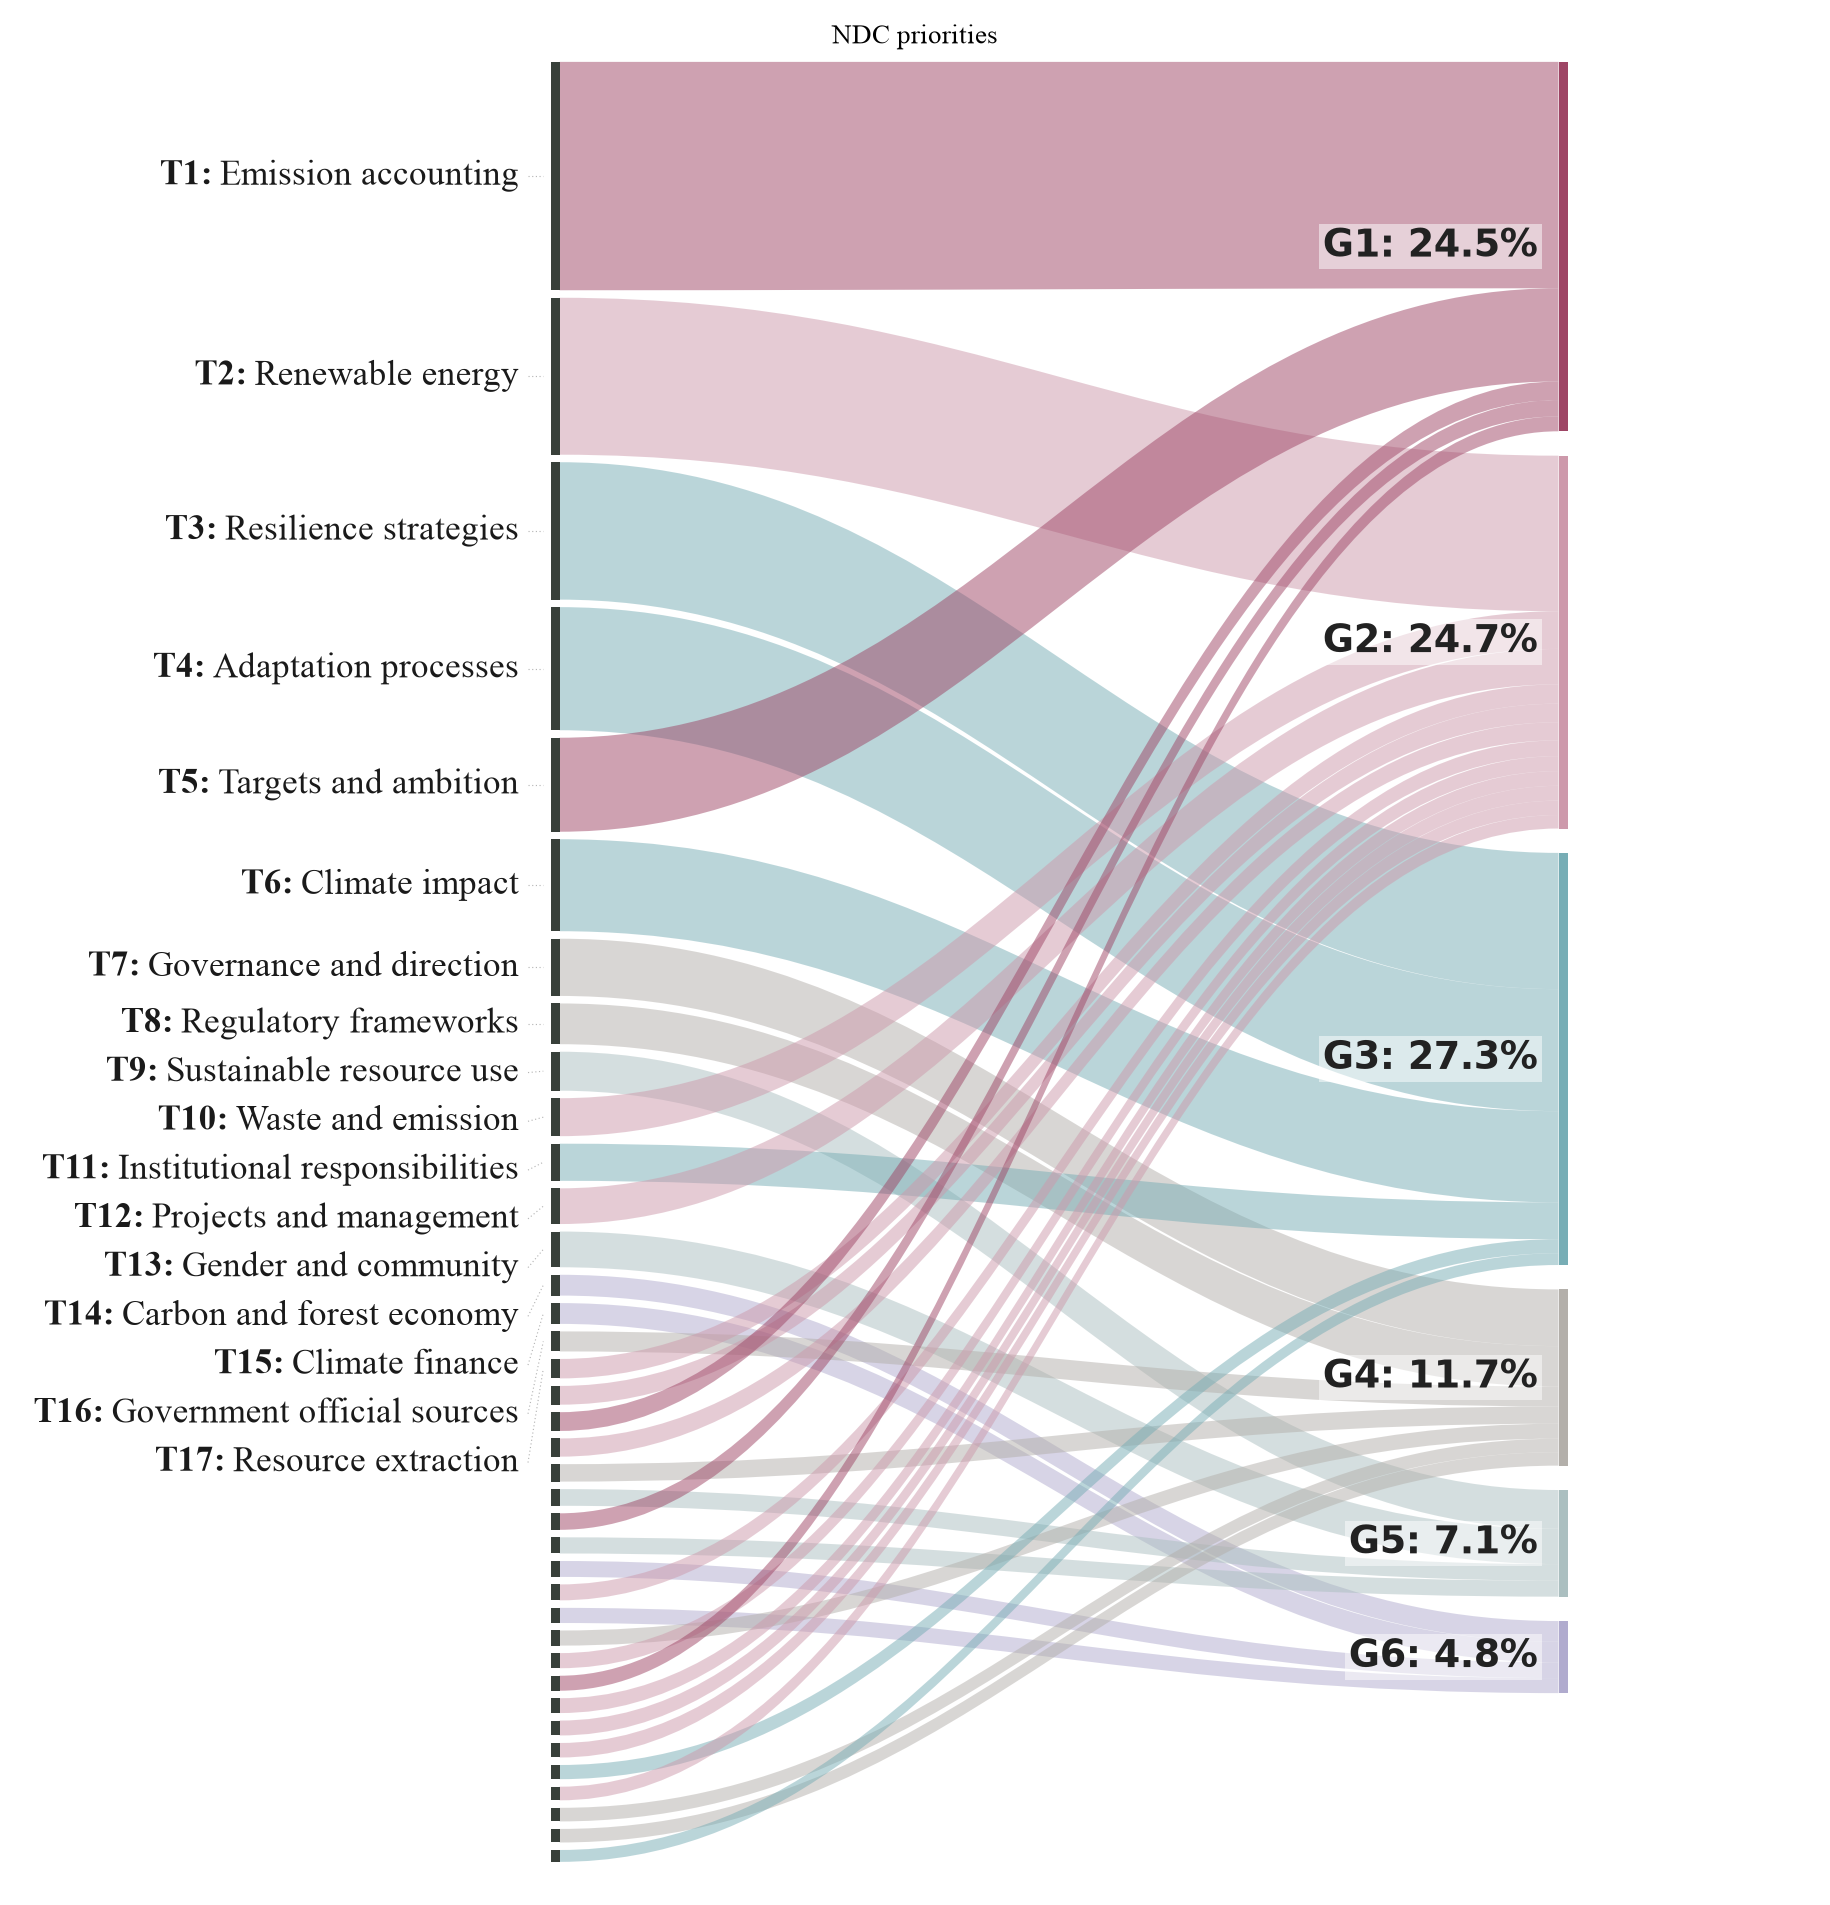

In [180]:
fig = sankey('ndc', title='NDC priorities', save='Fig1_left_ndc')
plt.show()

## Right panel, online

online: labelled 22 of 38 topics
saved output/figures/Fig1_right_online.{png,pdf,svg}


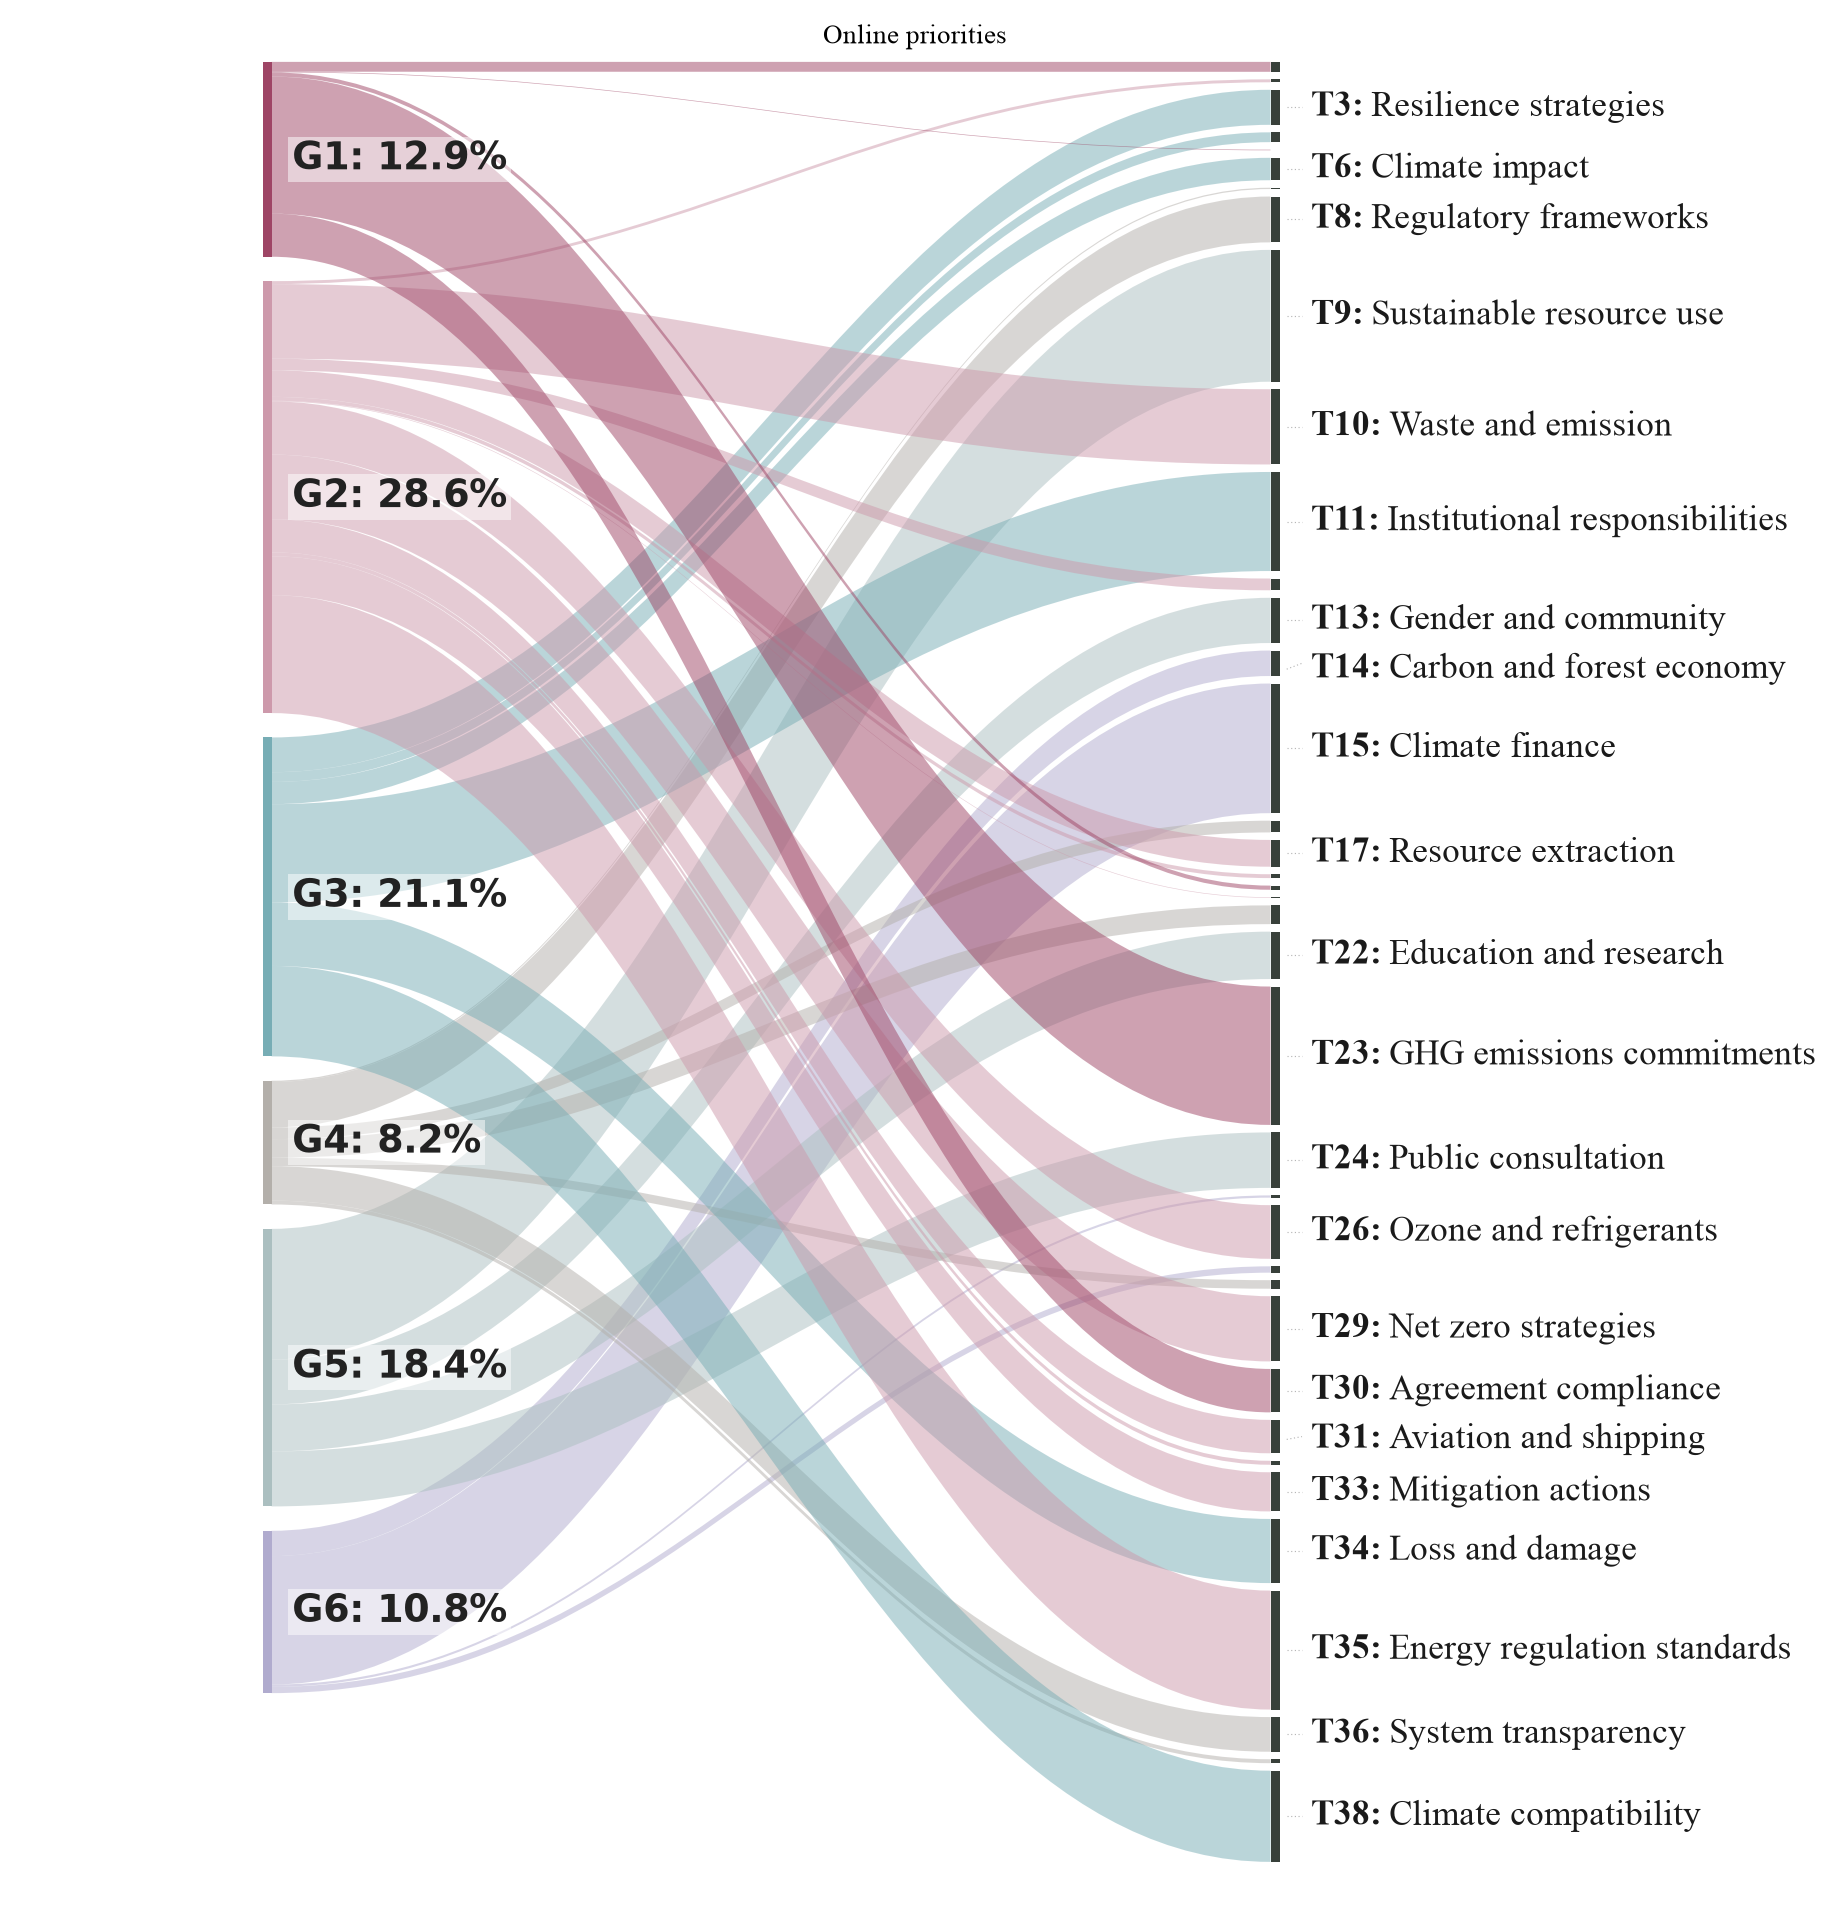

In [181]:
fig = sankey('online', title='Online priorities', save='Fig1_right_online')
plt.show()

## The complete Figure 1

Both panels plus the middle column in one file, using the same Settings above. Word clouds
are the existing artwork, recoloured to each group and cropped to drop the `Word Cloud for
Topic N` line. Set `SHOW_WORDCLOUDS = False` to leave the middle column as names only.

In [183]:
# ---- composite figure ----------------------------------------------------------
FULL_FIGSIZE = (20, 12.6)
WORDCLOUD_DIR = os.path.join(cfg.OUTPUT_DIR, 'wordcloud_images')  # original jpg artwork, not distributed; not needed when WC_SOURCE = 'terms'
SHOW_WORDCLOUDS = True
WC_TINT      = 0.68        # darken the group colour for the words, 1.0 = no darkening
WC_CONTRAST  = (0.10, 0.52) # (floor, range) applied to the ink; lower floor = darker
WC_CROP_TOP  = 0.13        # fraction cut from the top, removes the jpg's own caption

# column positions, left to right
X_LABEL_L, X_TOPIC_L, X_GROUP_L = 0.168, 0.178, 0.352
X_GROUP_R, X_TOPIC_R, X_LABEL_R = 0.648, 0.822, 0.832
MID_L, MID_R = 0.398, 0.602
FULL_LABEL_FONTSIZE = 8.8
HEADER_FONTSIZE     = 13
GROUPNAME_FONTSIZE  = 10.8
# ---- word clouds ---------------------------------------------------------------
WC_SOURCE  = 'terms'   # 'terms' = generated from the topic model (answers R1.2)
                       # 'image' = the original jpg artwork in WORDCLOUD_DIR
WC_N_TERMS = 15        # how many terms per group
WC_FONT_MIN, WC_FONT_MAX = 8, 56   # smallest and largest word
WC_SIZE_POW = 1.80     # >1 pushes the small words down, widening the contrast
WC_FONT     = 'DejaVu Sans Mono'   # the monospace look of the published clouds
WC_WEIGHT   = 'normal'
# Colour runs pale -> group colour -> deep, the way the published Greens ramp does.
WC_PALE     = 0.14     # smallest words: 0 is white, 1 is the group colour
WC_DEEP     = 0.22     # largest words: 0 is black, 1 is the group colour
WC_BANDS    = 5        # how many discrete shades; 0 = a smooth gradient instead
WC_BAND_POS = None     # None = evenly spaced along the pale -> deep ramp.
                       # Or give one position per band, e.g. [0.0, 0.2, 0.45, 0.75, 1.0],
                       # where 0 is the palest shade and 1 the deepest.
WC_BAND_COLORS = None  # full manual override, e.g.
                       # {'G3': ['#CFE3E5', '#A8CBCF', '#77ADB5', '#4E8189', '#2A4F56']}
                       # Palest first. Groups left out fall back to the ramp.

# ---- which terms appear ---------------------------------------------------------
WC_TERMS_CSV    = 'assets/wordcloud_terms.csv'
WC_USE_CSV      = True   # if the file exists, use it instead of the automatic ranking
WC_N_CANDIDATES = 30     # how many candidates to write out for editing
WC_PAD      = 1        # grid cells of clearance around each word; 0 packs tightest
WC_BOX      = (1.05, 0.80)  # shrink each word's measured box (width, height) before
                            # packing. Text boxes carry a lot of blank space above and
                            # below, so lowering the second number nests words closer.
WC_GRID     = (440, 280)  # packing resolution (width, height); higher = tighter
WC_SEED     = 7        # changes which gaps the small words fall into
WC_ASPECT   = 2.2      # cloud shape: higher = wider and flatter, 1.0 = round
WC_SHRINK       = 0.86 # if a word will not fit, retry it this much smaller
WC_SHRINK_TRIES = 7    # how many times to retry before dropping it
# The stop list and the display spellings live in the next cell, in WC_STOP / WC_SHOW.

In [184]:
import json

# Group terms for the word clouds.
#
# The published clouds showed whichever terms were heaviest inside a group, which put
# "framework" and "categorization" under Adaptation, the example Referee 1 raised. These
# are scored by weight AND exclusivity, so a term has to be heavy in this group and light
# in the other five, and has to appear in at least two of the group's topics.

WC_STOP = {
    'attempted','potentially','responsive','responsible','sustained','evidence','progression',
    'addressed','addressedarticle','setarticle','initial','achievingobjective','option','fit',
    'setting','execution','verifies','without','least','short','type','applicable','paragraph',
    'categorization','use','public','national','data','system','framework','target','plan',
    'measure','include','provide','relevant','following','also','may','shall','level','base',
    'develop','development','implementation','action','support','increase','improve','ensure',
    'pncc','cma','considers','metric','assumption','covered','value','product','identified',
    'global','promote','undp','journal','paragraphagreement','comparedbau','approved','decision',
    'line','year','compared','significant','used','focus','second','world','million','category',
    'office','partner','consistent','contribute','demand','goal','event','young','right','climate',
}

WC_SHOW = {
    'nationallydetermined':'nationally determined','ghgemission':'GHG emission',
    'greenhousegas':'greenhouse gas','energyefficiency':'energy efficiency',
    'genderequality':'gender equality','indigenouspeople':'indigenous people',
    'humanright':'human rights','climatechange':'climate change',
    'climateneutrality':'climate neutrality','climateresilient':'climate resilient',
    'emissionreduction':'emission reduction','emissionremoval':'emission removal',
    'renewableenergy':'renewable energy','mrvsystem':'MRV system','longterm':'long term',
    'economywide':'economy-wide','euets':'EU ETS','eumember':'EU member',
    'mrv':'MRV','unfccc':'UNFCCC','ndc':'NDC','ghg':'GHG','indc':'INDC','sdgs':'SDGs',
    'lulucf':'LULUCF',
}

_KW = json.load(open('assets/topic_keywords.json'))


def group_terms(n=None):
    """Weight x exclusivity, keeping terms that appear in at least two of the group's topics."""
    n = n or WC_N_TERMS
    prof, ntop = {}, {}
    for g in GROUPS:
        d, c = {}, {}
        for j in cfg.TOPIC_GROUPS_NDC[g]:
            for w, v in _KW[str(j)]:
                d[w] = d.get(w, 0.0) + v
                c[w] = c.get(w, 0) + 1
        s = sum(d.values())
        prof[g] = {w: v / s for w, v in d.items()}
        ntop[g] = c
    tot = {}
    for g in GROUPS:
        for w, v in prof[g].items():
            tot[w] = tot.get(w, 0.0) + v
    out = {}
    for g in GROUPS:
        sc = {w: v * (v / tot[w]) for w, v in prof[g].items()
              if ntop[g][w] >= 2 and w not in WC_STOP and len(w) > 3}
        out[g] = [(WC_SHOW.get(w, w), v)
                  for w, v in sorted(sc.items(), key=lambda x: -x[1])[:n]]
    return out


def _slots(gh, gw):
    """Candidate top-left cells, nearest the centre first."""
    cy, cx = gh / 2, gw / 2
    pts = [(y, x) for y in range(gh) for x in range(gw)]
    pts.sort(key=lambda p: (p[0] - cy) ** 2 * WC_ASPECT + (p[1] - cx) ** 2)
    return pts


def draw_cloud(ax, terms, base_rgb, x0, x1, y0, y1, group_key=None):
    """Greedy packing on an occupancy grid, biggest word first, small words in the gaps."""
    if not terms:
        return
    fig = ax.figure
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    vals = np.array([v for _, v in terms], float)
    vals = vals / vals.max()
    sizes = WC_FONT_MIN + (WC_FONT_MAX - WC_FONT_MIN) * np.power(vals, WC_SIZE_POW)

    GW, GH = WC_GRID
    occ = np.zeros((GH, GW), bool)
    W, H = x1 - x0, y1 - y0
    cand = _slots(GH, GW)
    base = np.asarray(base_rgb, float)
    pale = 1.0 - WC_PALE * (1.0 - base)
    deep = base * WC_DEEP
    ramp = mpl.colors.LinearSegmentedColormap.from_list('g', [pale, base, deep])
    if WC_BAND_COLORS and group_key in WC_BAND_COLORS:
        shades = [mpl.colors.to_rgb(c) for c in WC_BAND_COLORS[group_key]]
    elif WC_BANDS:
        pos = WC_BAND_POS or list(np.linspace(0, 1, WC_BANDS))
        shades = [ramp(x)[:3] for x in pos]
    else:
        shades = None

    def shade(v):
        if shades is None:
            return ramp(float(v))
        i = min(int(v * len(shades)), len(shades) - 1)
        return shades[i]
    rng = np.random.default_rng(WC_SEED)
    dropped = []

    for (w, _), fs, v in zip(terms, sizes, vals):
        # pale for the small words, deep for the big ones
        t = ax.text(0, -5, w, fontsize=fs, color=shade(v),
                    fontweight=WC_WEIGHT, fontfamily=WC_FONT,
                    ha='center', va='center', zorder=3)
        placed = False
        jitter = rng.integers(0, 3)
        for attempt in range(WC_SHRINK_TRIES + 1):
            t.set_fontsize(max(WC_FONT_MIN * 0.8, fs * WC_SHRINK ** attempt))
            bb = t.get_window_extent(renderer=r).transformed(ax.transAxes.inverted())
            cw = int(np.ceil(bb.width * WC_BOX[0] / W * GW)) + 2 * WC_PAD
            ch = int(np.ceil(bb.height * WC_BOX[1] / H * GH)) + 2 * WC_PAD
            if cw > GW or ch > GH:
                continue
            for cy_, cx_ in cand[jitter:]:
                # candidates are the word's CENTRE, so the cloud grows out from the
                # middle of the box instead of hanging off its top-left corner
                gy, gx = cy_ - ch // 2, cx_ - cw // 2
                if gy < 0 or gx < 0 or gy + ch > GH or gx + cw > GW:
                    continue
                if occ[gy:gy + ch, gx:gx + cw].any():
                    continue
                occ[gy:gy + ch, gx:gx + cw] = True
                t.set_position((x0 + (gx + cw / 2) / GW * W,
                                y1 - (gy + ch / 2) / GH * H))
                placed = True
                break
            if placed:
                break
        if not placed:
            t.remove()
            dropped.append(w)
    return dropped


def write_candidates(force=False):
    """Write the top candidates to a CSV so terms can be kept or dropped by hand."""
    if os.path.exists(WC_TERMS_CSV) and not force:
        print(WC_TERMS_CSV, 'already exists; call write_candidates(force=True) to rebuild it')
        return pd.read_csv(WC_TERMS_CSV)
    cand = group_terms(WC_N_CANDIDATES)
    rows = [{'group': g, 'rank': i + 1, 'term': w, 'weight': round(v, 6),
             'keep': 1 if i < WC_N_TERMS else 0}
            for g in GROUPS for i, (w, v) in enumerate(cand[g])]
    df = pd.DataFrame(rows)
    df.to_csv(WC_TERMS_CSV, index=False)
    print('wrote', WC_TERMS_CSV, '-', len(df), 'candidates. Edit the keep column and re-run.')
    return df


def load_terms():
    """The edited CSV if there is one, otherwise the automatic ranking."""
    if WC_USE_CSV and os.path.exists(WC_TERMS_CSV):
        df = pd.read_csv(WC_TERMS_CSV)
        out = {}
        for g in GROUPS:
            sub = df[(df.group == g) & (df.keep == 1)].sort_values('weight', ascending=False)
            out[g] = list(zip(sub.term.astype(str), sub.weight.astype(float)))[:WC_N_TERMS]
        return out
    return group_terms()


write_candidates()
GROUP_TERMS = load_terms()
for g in GROUPS:
    print(f"{g} ({len(GROUP_TERMS[g])}): " + ', '.join(w for w, _ in GROUP_TERMS[g]))

assets/wordcloud_terms.csv already exists; call write_candidates(force=True) to rebuild it
G1 (15): agreement, UNFCCC, convention, ambition, nationally determined, long term, GHG emission, contribution, economy-wide, emission, emission reduction, mitigation, policymeasure, reduction, objective
G2 (15): vehicle, fuel, transport, energy efficiency, standard, transportation, energy, road, removal, emission removal, methodology, description, diesel, freight, electricvehicle
G3 (15): assessment, vulnerability, health, climate change, adaptation, ministry, risk, gender, SDGs, agricultural, waterresource, ecosystem, international, subnational, coastalzone
G4 (15): measurement, planning, decree, method, transparency, greenhouse gas, committee, directorate, INDC, regulation, UNFCCC, institution, coordination, ministry, unitednation
G5 (15): youth, woman, gender equality, indigenous people, education, participation, university, human rights, initiative, community, opportunity, mining, awareness,

## One word cloud per group, as separate files

Six standalone images at the proportions of the original artwork, written to
`output/figures/Fig1_wordcloud_G1 … G6`. Colour is controlled either by the ramp
(`WC_PALE`, `WC_DEEP`, `WC_BANDS`) or, for full control, by pasting explicit shades into
`WC_BAND_COLORS`. Run the next cell to print a ready-made dictionary to edit.

In [ ]:
# Print the shades currently in use, as a dictionary you can paste into the Settings
# cell and edit. Palest first, deepest last.
def print_shades():
    print('WC_BAND_COLORS = {')
    for g in GROUPS:
        base = np.asarray(mpl.colors.to_rgb(COLORS[g]), float)
        pale = 1.0 - WC_PALE * (1.0 - base)
        deep = base * WC_DEEP
        ramp = mpl.colors.LinearSegmentedColormap.from_list('g', [pale, base, deep])
        pos = WC_BAND_POS or list(np.linspace(0, 1, WC_BANDS or 5))
        hexes = [mpl.colors.to_hex(ramp(x)) for x in pos]
        print(f"    '{g}': {hexes},   # {F.GROUP_LABELS[g]}")
    print('}')


print_shades()

In [ ]:
# ---- standalone word clouds ----------------------------------------------------
WC_SINGLE_FIGSIZE = (9, 5)     # inches; the originals are 2:1
WC_SINGLE_MARGIN  = 0.03       # blank border as a fraction of the box
WC_SINGLE_TITLE   = False      # True adds "G1: Emission accounting and targets" on top
WC_SINGLE_RULE    = False      # True adds the coloured rule above the title


def wordcloud_panel(g, save=None):
    fig = plt.figure(figsize=WC_SINGLE_FIGSIZE, dpi=150)
    ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
    m = WC_SINGLE_MARGIN
    top = 1 - m
    if WC_SINGLE_RULE:
        ax.plot([m, 1 - m], [top] * 2, color=COLORS[g], lw=2.4)
        top -= 0.03
    if WC_SINGLE_TITLE:
        _topic_label(ax, m, top - 0.03, g, F.GROUP_LABELS[g], 'left',
                     GROUPNAME_FONTSIZE, font=TITLE_FONT)
        top -= 0.09
    dropped = draw_cloud(ax, GROUP_TERMS[g], mpl.colors.to_rgb(COLORS[g]),
                         m, 1 - m, m, top, group_key=g)
    if dropped:
        print(f'  {g}: no room for {", ".join(dropped)}')
    if save:
        for ext in ('png', 'pdf', 'svg'):
            fig.savefig(os.path.join(OUT, f'{save}.{ext}'), bbox_inches='tight',
                        facecolor='white', dpi=DPI)
    return fig


for g in GROUPS:
    f = wordcloud_panel(g, save=f'Fig1_wordcloud_{g}')
    plt.show()
print('wrote Fig1_wordcloud_G1 .. G6 as png, pdf and svg')

In [185]:
import os
import matplotlib.image as mpimg


def _wordcloud(path, hexcolor):
    im = mpimg.imread(path).astype(float) / 255.0
    im = im[int(im.shape[0] * WC_CROP_TOP):, :, :3]
    ink = 1.0 - im.mean(axis=2)
    lo, rng = WC_CONTRAST
    ink = np.clip((ink - lo) / rng, 0, 1)
    c = np.array(mpl.colors.to_rgb(hexcolor)) * WC_TINT
    return np.clip(1.0 - ink[..., None] * (1.0 - c), 0, 1)


def _half_panel(ax, side, x_topic, x_group, label_x, ha):
    tpos, gpos = _layout(side)
    ht, hg = TOPIC_NODE_WIDTH / 2, GROUP_NODE_WIDTH / 2
    cursor = {g: gpos[g][1] for g in GROUPS}
    for t in TOPICS:
        g = GRP_OF[t]
        a, b = tpos[t]
        gh = (gpos[g][1] - gpos[g][0]) * (float(SHARES[side][t]) / float(GSHARE[side][g]))
        gb = cursor[g]; ga_ = gb - gh; cursor[g] = ga_
        if side == 'ndc':
            _ribbon(ax, x_topic + ht, x_group - hg, a, b, ga_, gb, COLORS[g])
        else:
            _ribbon(ax, x_group + hg, x_topic - ht, ga_, gb, a, b, COLORS[g])
        ax.add_patch(Rectangle((x_topic - ht, a), TOPIC_NODE_WIDTH, b - a,
                               facecolor=TOPIC_NODE_COLOR, edgecolor='none', zorder=3))
    for g in GROUPS:
        a, b = gpos[g]
        ax.add_patch(Rectangle((x_group - hg, a), GROUP_NODE_WIDTH, b - a,
                               facecolor=GROUP_NODE_COLOR or COLORS[g],
                               edgecolor='none', zorder=3))
        if SHOW_GROUP_PCT and side in PCT_SIDES:
            dx, pha = ((-PCT_OFFSET, 'right') if side == 'ndc'
                       else (PCT_OFFSET, 'left'))
            ax.text(x_group + dx, (a + b) / 2,
                    PCT_LABEL(g, 100 * GSHARE[side][g]),
                    ha=pha, va='center', fontsize=PCT_FONTSIZE,
                    fontweight=PCT_WEIGHT, color=PCT_COLOR, zorder=4,
                    bbox=dict(fc=PCT_BOX_COLOR, ec='none', alpha=PCT_BOX_ALPHA,
                              pad=PCT_BOX_PAD) if PCT_BOX else None)
    if not SHOW_LABELS:
        return []
    sel = [t for t in TOPICS if float(SHARES[side][t]) >= LABEL_MIN_SHARE]
    ys = _spread([(tpos[t][0] + tpos[t][1]) / 2 for t in sel],
                 TOPIC_BOT, TOPIC_TOP, LABEL_SPACING)
    for t, yl in zip(sel, ys):
        yn = (tpos[t][0] + tpos[t][1]) / 2
        xa, xb = ((label_x + 0.004, x_topic - ht - 0.004) if ha == 'right'
                  else (x_topic + ht + 0.004, label_x - 0.004))
        ax.plot([xa, xb], [yl, yn], color=LEADER_COLOR, lw=0.55, ls=(0, (1, 2.2)), zorder=1)
        _topic_label(ax, label_x, yl, t, F.TOPIC_LABELS[t], ha, FULL_LABEL_FONTSIZE)
    return sel


def figure1(save='Figure1_full'):
    fig = plt.figure(figsize=FULL_FIGSIZE, dpi=150)
    ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')

    left  = _half_panel(ax, 'ndc',    X_TOPIC_L, X_GROUP_L, X_LABEL_L, 'right')
    right = _half_panel(ax, 'online', X_TOPIC_R, X_GROUP_R, X_LABEL_R, 'left')

    ax.text((X_TOPIC_L + X_GROUP_L) / 2, 0.992, 'NDC priorities',
            ha='center', va='top', fontsize=HEADER_FONTSIZE, fontfamily=TITLE_FONT)
    ax.text((X_GROUP_R + X_TOPIC_R) / 2, 0.992, 'Online priorities',
            ha='center', va='top', fontsize=HEADER_FONTSIZE, fontfamily=TITLE_FONT)
    ax.text(X_LABEL_L / 2, 0.992, 'Topics', ha='center', va='top',
            fontsize=HEADER_FONTSIZE, fontweight='bold', fontfamily=TITLE_FONT)
    ax.text((X_LABEL_R + 1) / 2, 0.992, 'Topics', ha='center', va='top',
            fontsize=HEADER_FONTSIZE, fontweight='bold', fontfamily=TITLE_FONT)
    ax.text((MID_L + MID_R) / 2, 0.992, 'Thematic groups', ha='center', va='top',
            fontsize=HEADER_FONTSIZE, fontweight='bold', fontfamily=TITLE_FONT)

    slot = (TOPIC_TOP - TOPIC_BOT) / 6
    for k, g in enumerate(GROUPS):
        top = TOPIC_TOP - k * slot
        ax.plot([MID_L, MID_R], [top - 0.002] * 2, color=COLORS[g], lw=2.4)
        _topic_label(ax, MID_L, top - 0.016 - 0.012, g, F.GROUP_LABELS[g],
                     'left', GROUPNAME_FONTSIZE, font=TITLE_FONT)
        if SHOW_WORDCLOUDS and WC_SOURCE == 'terms':
            draw_cloud(ax, GROUP_TERMS[g], mpl.colors.to_rgb(COLORS[g]),
                       MID_L + 0.006, MID_R - 0.006, top - slot + 0.016, top - 0.046,
                       group_key=g)
        elif SHOW_WORDCLOUDS:
            p = os.path.join(WORDCLOUD_DIR, f'Word_cloud_general_topic{k+1}.jpg')
            if os.path.exists(p):
                ax.imshow(_wordcloud(p, COLORS[g]),
                          extent=(MID_L + 0.006, MID_R - 0.006, top - slot + 0.016, top - 0.046),
                          aspect='auto', zorder=2, interpolation='bilinear')

    if save:
        for ext in ('png', 'pdf', 'svg'):
            fig.savefig(os.path.join(OUT, f'{save}.{ext}'), bbox_inches='tight',
                        facecolor='white', dpi=DPI)
        print('saved', os.path.join(OUT, save) + '.{png,pdf,svg}')
    print(f'labelled {len(left)} topics on the left, {len(right)} on the right')
    return fig

saved output/figures/Figure1_full.{png,pdf,svg}
labelled 17 topics on the left, 22 on the right


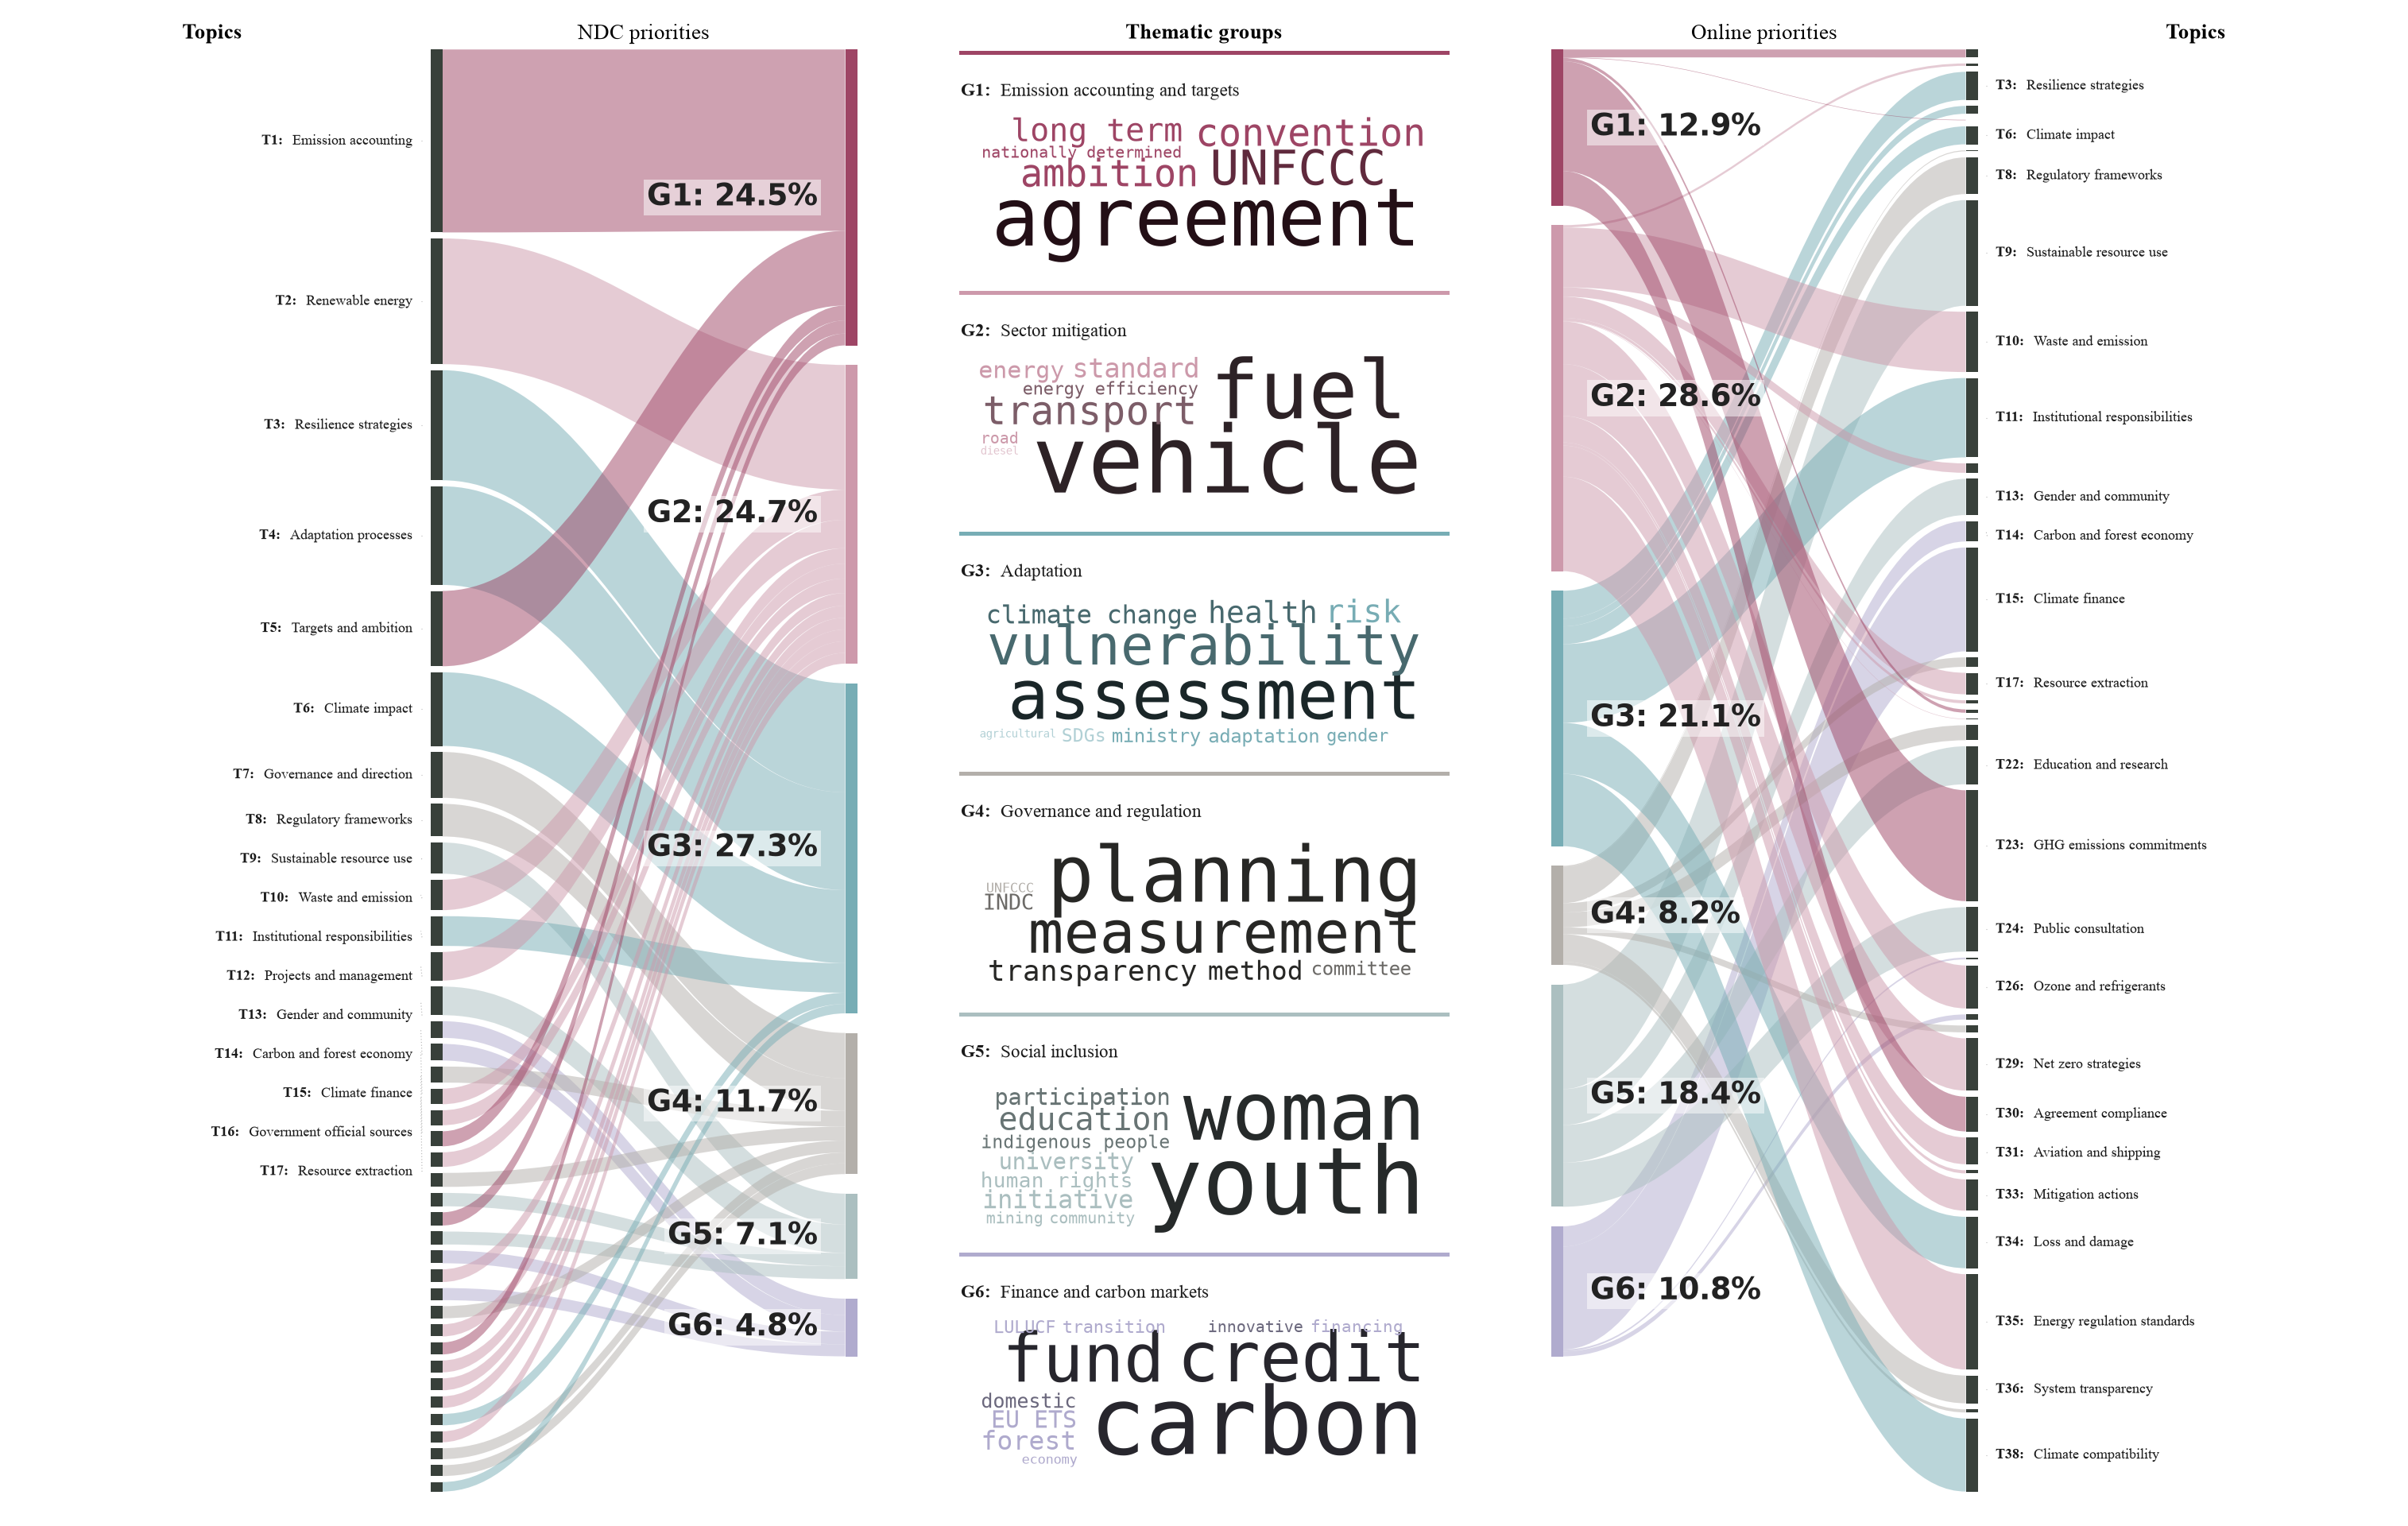

In [186]:
fig = figure1(save='Figure1_full')
plt.show()

## The numbers behind the ribbons

Written out so the two panels can be checked, or labelled by hand after export.

In [43]:
tbl = pd.DataFrame({
    'group':    [GRP_OF[t] for t in TOPICS],
    'label':    [F.TOPIC_LABELS[t] for t in TOPICS],
    'NDC %':    [100*float(SHARES['ndc'][t]) for t in TOPICS],
    'online %': [100*float(SHARES['online'][t]) for t in TOPICS],
}, index=TOPICS)
tbl.to_csv(os.path.join(OUT, 'Fig1_values.csv'))
tbl.round(2)

,group,label,NDC %,online %
T1,G1,Emission accounting,15.00,0.65
T2,G2,Renewable energy,10.31,0.19
T3,G3,Resilience strategies,9.03,2.30
T4,G3,Adaptation processes,8.09,0.65
T5,G1,Targets and ambition,6.17,0.04
T6,G3,Climate impact,6.04,1.47
T7,G4,Governance and direction,3.76,0.08
T8,G4,Regulatory frameworks,2.68,3.01
T9,G5,Sustainable resource use,2.56,8.66
T10,G2,Waste and emission,2.50,4.94


## Trying a different palette

Overwrite `COLORS`, re-run the Settings cell is not needed, just re-run this and the two
panel cells above.

In [ ]:
# example: a cooler set. Comment out to keep the published colours.
# COLORS = {'G1': '#8C5A72', 'G2': '#D9A7AE', 'G3': '#7FA9AF',
#           'G4': '#ADA69A', 'G5': '#BCC9B8', 'G6': '#A49EC2'}
# ALPHA = 0.9
# fig = sankey('ndc', title='NDC priorities'); plt.show()